# Análisis de correlación contemporánea

En este notebook se evalúa la asociación estadística entre la actividad solar, representada por el número mensual de manchas solares (SSN), y las variables climáticas ICEN, ONI y precipitación ERA5.

Se utilizan los coeficientes de correlación de Pearson y Spearman.

- Pearson evalúa principalmente asociación lineal.
- Spearman evalúa asociación monotónica a partir del orden de los valores.

En esta etapa se analizan únicamente relaciones contemporáneas, es decir, observaciones correspondientes al mismo mes. Los posibles desfases temporales serán evaluados posteriormente.

La presencia de correlación no será interpretada como evidencia de causalidad.

In [1]:
import os
import subprocess

repo = "correlacion_actividad_solar_elnino"
ruta_repo = f"/content/{repo}"

if not os.path.exists(ruta_repo):
    subprocess.run(
        [
            "git",
            "clone",
            "https://github.com/gretadive/correlacion_actividad_solar_elnino.git"
        ],
        check=True
    )
    print("✅ Repositorio clonado")
else:
    print("✅ Repositorio disponible")

✅ Repositorio clonado


In [2]:
%cd /content/correlacion_actividad_solar_elnino

/content/correlacion_actividad_solar_elnino


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dataset = pd.read_csv(
    "data/processed/dataset_integrado_precipitacion.csv",
    parse_dates=["fecha"]
)

dataset.head()

,fecha,anio,mes,ICEN,ONI,SSN,precipitacion_mm
0,1950-01-01,1950,1,-0.75,-1.32,143.9,155.309817
1,1950-02-01,1950,2,-1.07,-1.20,134.3,164.955825
2,1950-03-01,1950,3,-1.25,-1.12,155.4,158.180623
3,1950-04-01,1950,4,-1.18,-1.08,160.6,221.687990
4,1950-05-01,1950,5,-1.22,-1.10,150.5,123.802819


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dataset = pd.read_csv(
    "data/processed/dataset_integrado_precipitacion.csv",
    parse_dates=["fecha"]
)

dataset.head()

In [4]:
variables = [
    "ICEN",
    "ONI",
    "SSN",
    "precipitacion_mm"
]

matriz_pearson = dataset[variables].corr(
    method="pearson"
)

matriz_pearson

,ICEN,ONI,SSN,precipitacion_mm
ICEN,1.000000,0.706988,0.091769,0.169853
ONI,0.706988,1.000000,0.081204,0.079403
SSN,0.091769,0.081204,1.000000,-0.056102
precipitacion_mm,0.169853,0.079403,-0.056102,1.000000


In [5]:
matriz_spearman = dataset[variables].corr(
    method="spearman"
)

matriz_spearman

,ICEN,ONI,SSN,precipitacion_mm
ICEN,1.000000,0.702699,0.119691,0.116295
ONI,0.702699,1.000000,0.084878,0.022049
SSN,0.119691,0.084878,1.000000,-0.064385
precipitacion_mm,0.116295,0.022049,-0.064385,1.000000


In [6]:
from scipy.stats import pearsonr, spearmanr

pares = [
    ("SSN", "ICEN"),
    ("SSN", "ONI"),
    ("SSN", "precipitacion_mm")
]

resultados = []

for x, y in pares:

    r_pearson, p_pearson = pearsonr(
        dataset[x],
        dataset[y]
    )

    rho_spearman, p_spearman = spearmanr(
        dataset[x],
        dataset[y]
    )

    resultados.append({
        "Variable_X": x,
        "Variable_Y": y,
        "Pearson_r": r_pearson,
        "Pearson_p": p_pearson,
        "Spearman_rho": rho_spearman,
        "Spearman_p": p_spearman
    })

resultados_corr = pd.DataFrame(resultados)

resultados_corr

,Variable_X,Variable_Y,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
0,SSN,ICEN,0.091769,0.005419,0.119691,0.000281
1,SSN,ONI,0.081204,0.013904,0.084878,0.010129
2,SSN,precipitacion_mm,-0.056102,0.089524,-0.064385,0.051288


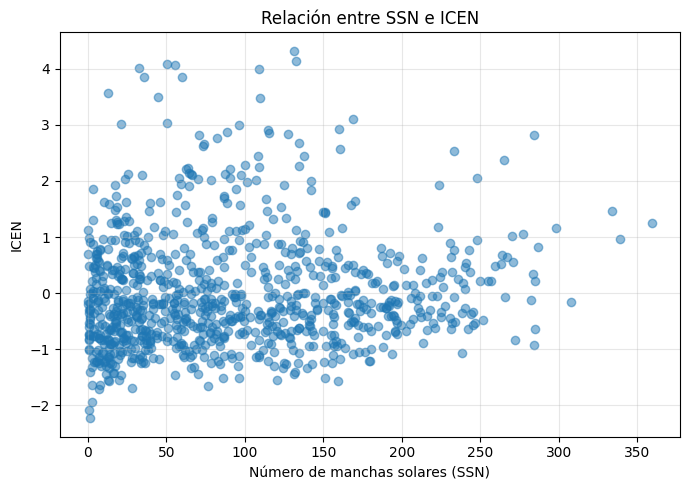

In [7]:
#SSN vs icen
plt.figure(figsize=(7,5))

plt.scatter(
    dataset["SSN"],
    dataset["ICEN"],
    alpha=0.5
)

plt.xlabel("Número de manchas solares (SSN)")
plt.ylabel("ICEN")
plt.title("Relación entre SSN e ICEN")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

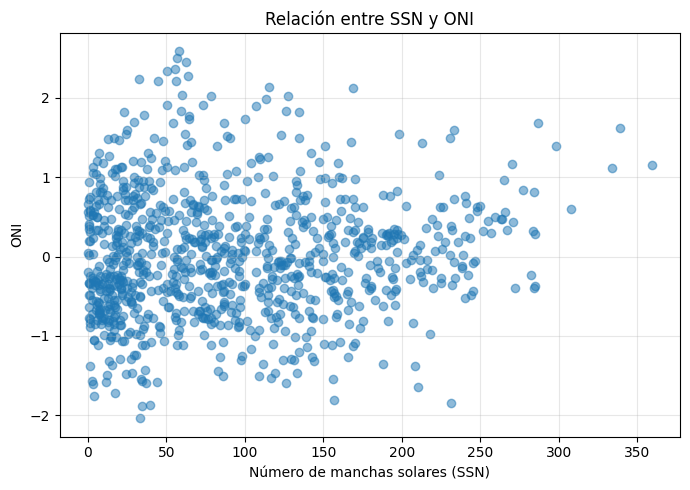

In [8]:
#SSN vs oni
plt.figure(figsize=(7,5))

plt.scatter(
    dataset["SSN"],
    dataset["ONI"],
    alpha=0.5
)

plt.xlabel("Número de manchas solares (SSN)")
plt.ylabel("ONI")
plt.title("Relación entre SSN y ONI")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

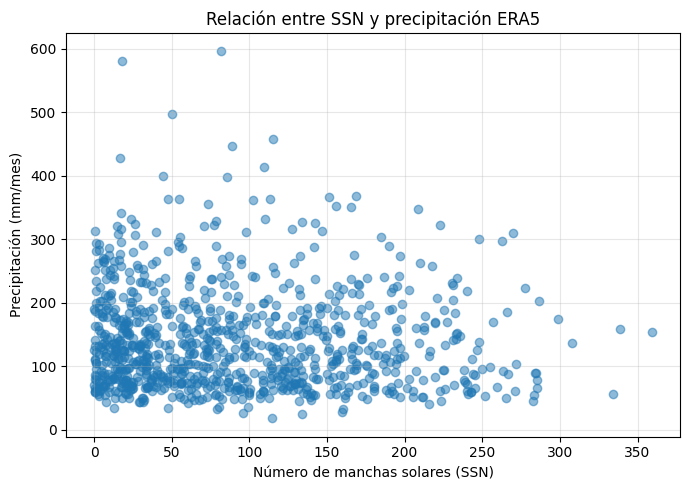

In [10]:
#SSN vs precipitación

plt.figure(figsize=(7,5))

plt.scatter(
    dataset["SSN"],
    dataset["precipitacion_mm"],
    alpha=0.5
)

plt.xlabel("Número de manchas solares (SSN)")
plt.ylabel("Precipitación (mm/mes)")
plt.title("Relación entre SSN y precipitación ERA5")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [11]:
resultados_corr.to_csv(
    "results/correlacion_contemporanea.csv",
    index=False,
    encoding="utf-8"
)

print("✅ Resultados de correlación guardados")

✅ Resultados de correlación guardados


## Interpretación

El análisis contemporáneo constituye una primera evaluación de la asociación estadística entre SSN e ICEN, ONI y precipitación.

Los coeficientes obtenidos serán interpretados considerando tanto su magnitud como su dirección. Debido a la naturaleza temporal de las series, estos resultados no serán considerados evidencia de causalidad y
serán complementados mediante análisis de desfases temporales y periodicidades.